In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [2]:
df = pd.read_csv('Mall_Customers (1).csv')

In [3]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [7]:
df['Gender'].value_counts()

Gender
Female    112
Male       88
Name: count, dtype: int64

In [9]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.columns = df.columns.str.strip()

In [14]:
len(df)

200

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [16]:
from sklearn.cluster import KMeans

In [17]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

In [28]:
kmeans = KMeans(n_clusters=3, random_state=42)

In [29]:
df['Group'] = kmeans.fit_predict(X)

C:\Users\PC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [30]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Group
0,1,Male,19,15,39,2
1,2,Male,21,15,81,2
2,3,Female,20,16,6,2
3,4,Female,23,16,77,2
4,5,Female,31,17,40,2


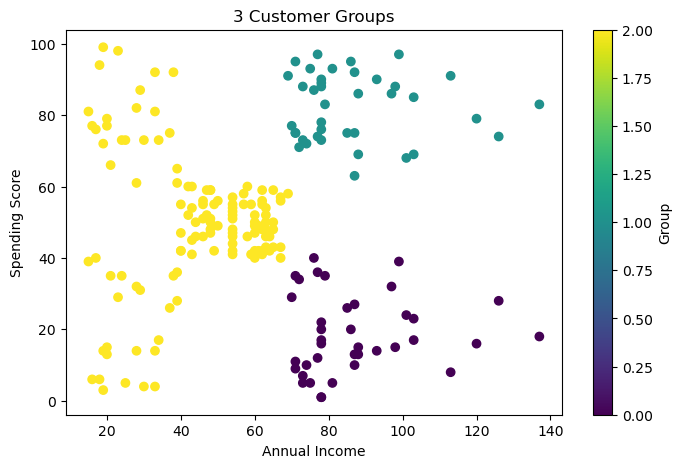

In [31]:
plt.figure(figsize=(8,5))
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], c = df['Group'], cmap= 'viridis')
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("3 Customer Groups")
plt.colorbar(label = "Group")
plt.show()

In [32]:
print(df.groupby('Group') [['Annual Income (k$)', 'Spending Score (1-100)', 'Age' ]].mean())

       Annual Income (k$)  Spending Score (1-100)        Age
Group                                                       
0               87.000000               18.631579  40.394737
1               86.538462               82.128205  32.692308
2               44.154472               49.829268  40.325203
